# 8.5. Thực nghiệm và đánh giá pipeline ALPR đầu cuối (End-to-End ALPR Evaluation)

Notebook này trực quan hóa và đối chứng thực nghiệm cho **Mục 8.5** của báo cáo dự án ALPR Việt Nam.
Dữ liệu được trích xuất trực tiếp từ các bộ benchmark thực nghiệm chính thức của dự án:
- `experiments/opt06-minimal/results.csv`: Đánh giá chất lượng nhận dạng đầu cuối (End-to-End & OCR-only Accuracy).
- `experiments/opt04-performance/results.csv`: Đo lường chi tiết độ trễ (latency), thông lượng (throughput) và chi phí tài nguyên qua từng stage.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Thiết lập đường dẫn gốc dự án
PROJECT_ROOT = Path("../..").resolve()
print(f"Project root: {PROJECT_ROOT}")

# Đọc kết quả thực nghiệm chính thức
df_acc = pd.read_csv(PROJECT_ROOT / "experiments" / "opt06-minimal" / "results.csv")
df_perf = pd.read_csv(PROJECT_ROOT / "experiments" / "opt04-performance" / "results.csv")

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print(f"Đã nạp {len(df_acc)} mẫu đánh giá chính xác và {len(df_perf)} bản ghi benchmark hiệu năng.")

Project root: D:\HOC_TAP\Bao_cao\CCNLTHD
Đã nạp 18 mẫu đánh giá chính xác và 51 bản ghi benchmark hiệu năng.


--- 
## 1. Phân bố kết quả nhận dạng đầu cuối (End-to-End Classification)

Đánh giá 17 instances đủ điều kiện (1 mẫu bị loại do ảnh quá mờ `img_0605`). Phân loại thành 4 nhóm kết quả rõ rệt:
1. **Đọc đúng hoàn toàn (Exact Match - EM):** Khớp 100% nhãn chuẩn.
2. **Đọc sai (Format Accepted but Wrong Text):** Formatter chấp nhận nhưng sai ký tự (nhầm lẫn OCR).
3. **Không nhận dạng được (Unrecognized format / Empty OCR):** Hệ thống chủ động từ chối xuất kết quả (trả về chuỗi rỗng) để đảm bảo độ tin cậy.
4. **Lỗi Runtime (Admission memory refused):** Hệ thống từ chối chạy CRAFT để chống sập bộ nhớ (out of memory).

C:\Users\HP\AppData\Local\Temp\ipykernel_1440\3890054312.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_counts.index, y=cat_counts.values, palette=colors, ax=ax2)


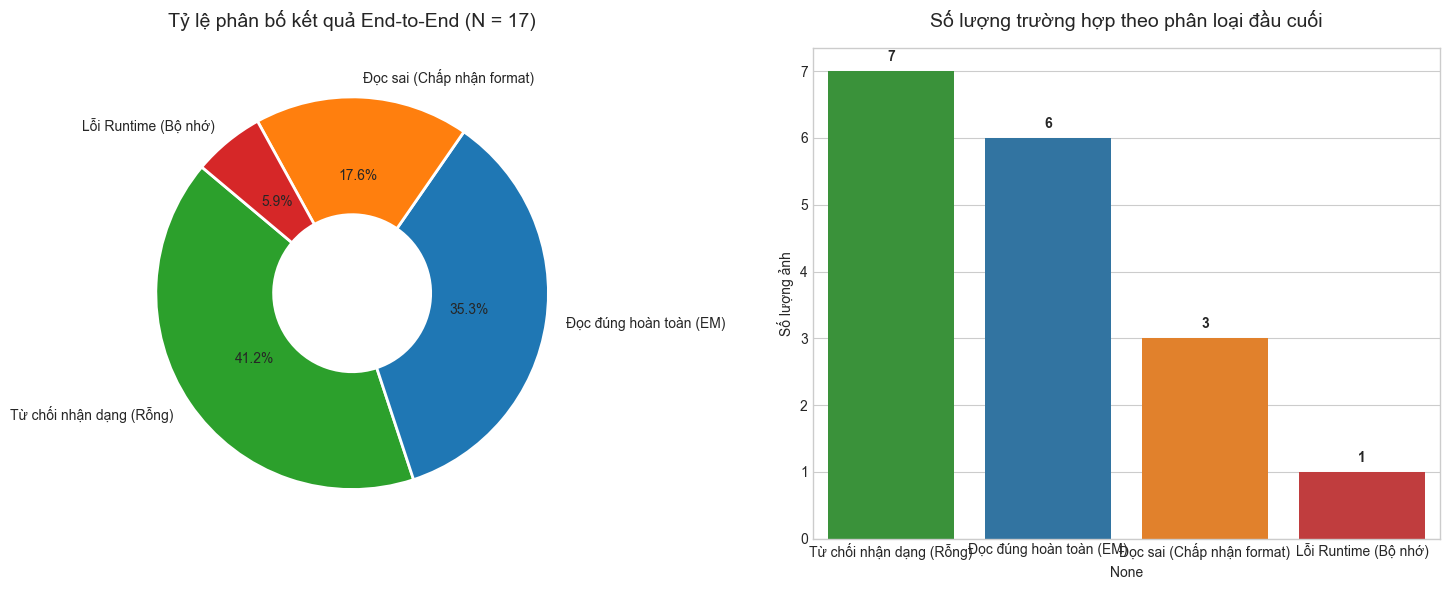

In [2]:
# Phân loại kết quả E2E
categories = []
for _, row in df_acc[df_acc['evaluation_status'] == 'evaluated'].iterrows():
    if row['e2e_status'] == 'ocr_runtime_error':
        categories.append('Lỗi Runtime (Bộ nhớ)')
    elif row['e2e_exact'] == True or row['e2e_exact'] == 'True':
        categories.append('Đọc đúng hoàn toàn (EM)')
    elif row['e2e_status'] == 'ok':
        categories.append('Đọc sai (Chấp nhận format)')
    else:
        categories.append('Từ chối nhận dạng (Rỗng)')

cat_counts = pd.Series(categories).value_counts()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Biểu đồ tròn
colors = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728']
ax1.pie(cat_counts, labels=cat_counts.index, autopct='%1.1f%%', startangle=140, 
        colors=colors, wedgeprops=dict(width=0.6, edgecolor='white', linewidth=2))
ax1.set_title("Tỷ lệ phân bố kết quả End-to-End (N = 17)", fontsize=14, pad=15)

# Biểu đồ cột chi tiết
sns.barplot(x=cat_counts.index, y=cat_counts.values, palette=colors, ax=ax2)
ax2.set_title("Số lượng trường hợp theo phân loại đầu cuối", fontsize=14, pad=15)
ax2.set_ylabel("Số lượng ảnh")
for i, v in enumerate(cat_counts.values):
    ax2.text(i, v + 0.15, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

--- 
## 2. So sánh độ chính xác: Chế độ OCR-only vs End-to-End (E2E)

- **Chế độ OCR-only (Oracle GT crop):** Cắt trực tiếp theo nhãn chuẩn của con người, kiểm tra giới hạn của riêng module OCR.
- **Chế độ End-to-End (E2E):** Chạy xuyên suốt pipeline hoàn chỉnh bắt đầu từ ảnh gốc với YOLOv8n detector.
- Phân tích theo các phân nhóm điều kiện: **Toàn bộ subset**, **Biển 1 dòng**, **Biển 2 dòng**, và **Biển góc nghiêng (Tilted)**.

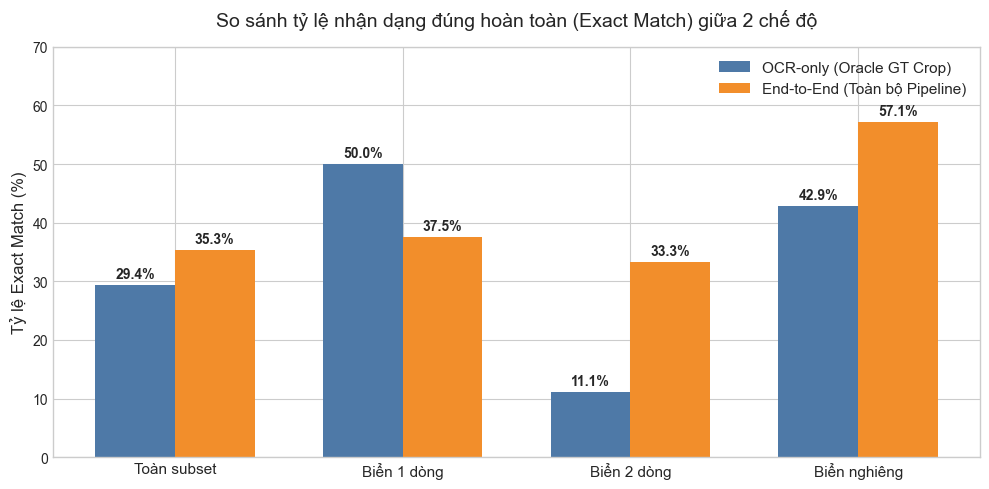

In [3]:
# Dữ liệu độ chính xác từ report.md của opt06-minimal
groups = ['Toàn subset', 'Biển 1 dòng', 'Biển 2 dòng', 'Biển nghiêng']
ocr_em = [29.41, 50.00, 11.11, 42.86]
e2e_em = [35.29, 37.50, 33.33, 57.14]

x = np.arange(len(groups))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width/2, ocr_em, width, label='OCR-only (Oracle GT Crop)', color='#4e79a7')
rects2 = ax.bar(x + width/2, e2e_em, width, label='End-to-End (Toàn bộ Pipeline)', color='#f28e2b')

ax.set_ylabel('Tỷ lệ Exact Match (%)', fontsize=12)
ax.set_title('So sánh tỷ lệ nhận dạng đúng hoàn toàn (Exact Match) giữa 2 chế độ', fontsize=14, pad=15)
ax.set_xticks(x)
ax.set_xticklabels(groups, fontsize=11)
ax.set_ylim(0, 70)
ax.legend(fontsize=11)

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

--- 
## 3. Bóc tách thời gian xử lý qua các công đoạn (Stage Latency Breakdown)

Đo lường chi tiết trên phần cứng thực tế (CPU Intel Core i5-1240P, 16GB RAM) với 13 mẫu hoàn tất thành công của chế độ End-to-End (B3):
- **Decode ảnh:** 31.11 ms (1.46%)
- **YOLOv8n Detector:** 53.06 ms (2.49%)
- **Padded Crop:** 0.01 ms (0.00%)
- **Preprocess (Deskew + CLAHE + Upscale):** 4.62 ms (0.22%)
- **EasyOCR (CRAFT + CRNN) + Line Grouping + Formatter:** **2043.88 ms (95.83%)**

**Nhận xét cốt lõi:** Khâu nhận dạng OCR chiếm tới 95.8% thời gian của toàn pipeline. Do đó, FPS cao của riêng detector (~22 FPS) không phản ánh tốc độ đầu cuối của hệ thống ALPR.

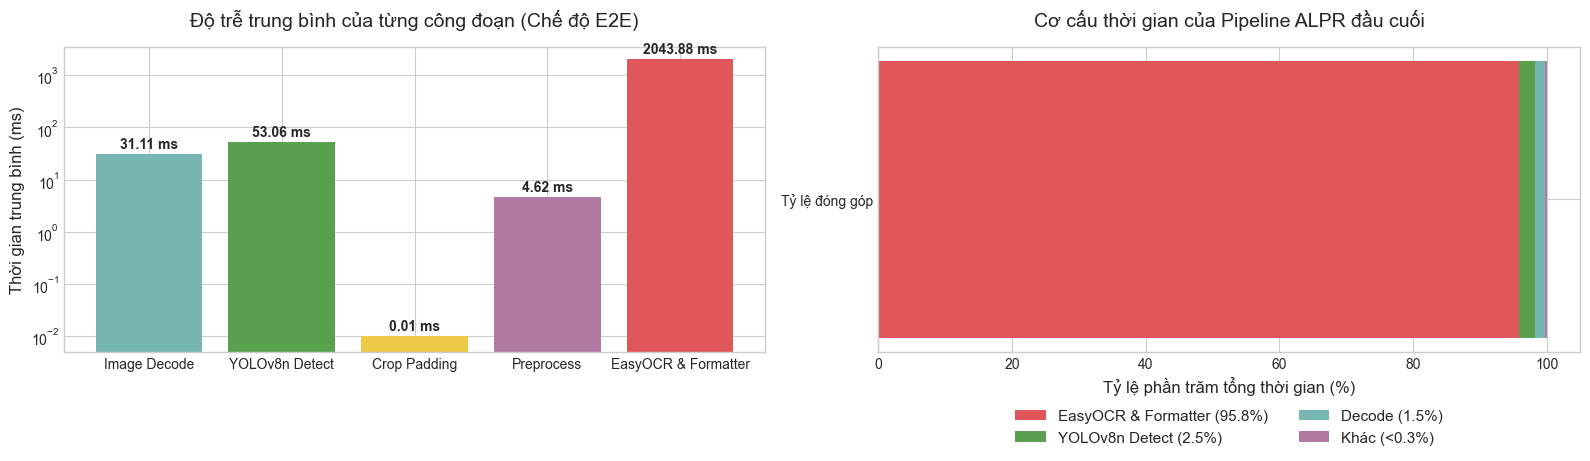

In [4]:
stages = ['Image Decode', 'YOLOv8n Detect', 'Crop Padding', 'Preprocess', 'EasyOCR & Formatter']
times_ms = [31.11, 53.06, 0.01, 4.62, 2043.88]
percentages = [t / sum(times_ms) * 100 for t in times_ms]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Biểu đồ cột thể hiện thời gian tuyệt đối (log scale hoặc normal)
colors_stage = ['#76b7b2', '#59a14f', '#edc948', '#b07aa1', '#e15759']
bars = ax1.bar(stages, times_ms, color=colors_stage)
ax1.set_ylabel('Thời gian trung bình (ms)', fontsize=12)
ax1.set_title('Độ trễ trung bình của từng công đoạn (Chế độ E2E)', fontsize=14, pad=15)
ax1.set_yscale('log')
ax1.set_ylim(0.005, 3500)
for bar, t in zip(bars, times_ms):
    ax1.text(bar.get_x() + bar.get_width()/2, t * 1.3, f'{t:.2f} ms', ha='center', fontweight='bold')

# Biểu đồ thanh ngang tỷ lệ phần trăm đóng góp
ax2.barh(['Tỷ lệ đóng góp'], [percentages[4]], label='EasyOCR & Formatter (95.8%)', color='#e15759')
ax2.barh(['Tỷ lệ đóng góp'], [percentages[1]], left=[percentages[4]], label='YOLOv8n Detect (2.5%)', color='#59a14f')
ax2.barh(['Tỷ lệ đóng góp'], [percentages[0]], left=[percentages[4] + percentages[1]], label='Decode (1.5%)', color='#76b7b2')
ax2.barh(['Tỷ lệ đóng góp'], [percentages[3] + percentages[2]], left=[percentages[4] + percentages[1] + percentages[0]], label='Khác (<0.3%)', color='#b07aa1')

ax2.set_xlabel('Tỷ lệ phần trăm tổng thời gian (%)', fontsize=12)
ax2.set_title('Cơ cấu thời gian của Pipeline ALPR đầu cuối', fontsize=14, pad=15)
ax2.legend(loc='lower center', bbox_to_anchor=(0.5, -0.35), ncol=2, fontsize=11)

plt.tight_layout()
plt.show()

--- 
## 4. Phân phối độ trễ End-to-End qua từng mẫu kiểm thử

Khảo sát độ biến thiên thời gian xử lý: Median là **1192 ms**, nhưng Mean là **2132 ms** và Max lên tới **6948 ms** đối với các ảnh có độ phân giải lớn đòi hỏi xử lý nhiều vùng ký tự.

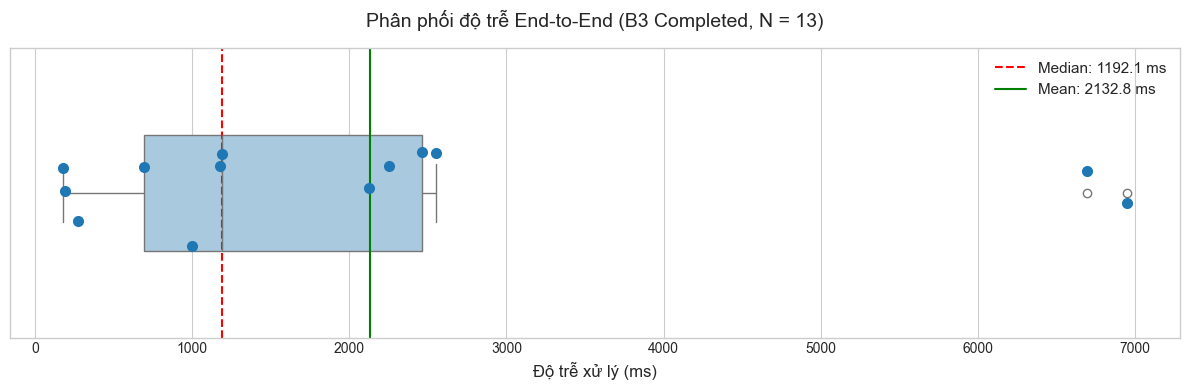

In [5]:
# Lọc các lượt B3 hoàn tất từ df_perf
df_b3 = df_perf[(df_perf['mode'] == 'B3') & (df_perf['status'] == 'completed')].copy()

fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(x=df_b3['latency_ms'], color='#a0cbe8', ax=ax, width=0.4)
sns.stripplot(x=df_b3['latency_ms'], color='#1f77b4', size=8, jitter=0.2, ax=ax)

ax.set_title("Phân phối độ trễ End-to-End (B3 Completed, N = 13)", fontsize=14, pad=15)
ax.set_xlabel("Độ trễ xử lý (ms)", fontsize=12)
ax.axvline(df_b3['latency_ms'].median(), color='red', linestyle='--', label=f"Median: {df_b3['latency_ms'].median():.1f} ms")
ax.axvline(df_b3['latency_ms'].mean(), color='green', linestyle='-', label=f"Mean: {df_b3['latency_ms'].mean():.1f} ms")
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()

--- 
## 5. Bảng tổng hợp đối chiếu Ground Truth và Kết quả End-to-End đầy đủ

Chi tiết từng trường hợp trong tập 17 ảnh đánh giá, hiển thị rõ mối liên hệ giữa Ground Truth, Raw text nhận diện, Kết quả cuối cùng và Trạng thái phản hồi của hệ thống.

In [6]:
# Trích xuất bảng kết quả chi tiết
eval_df = df_acc[df_acc['evaluation_status'] == 'evaluated'][[
    'filename', 'layout', 'ground_truth', 'e2e_raw', 'e2e_output', 'e2e_status', 'e2e_exact'
]].copy()

eval_df.columns = ['Tên file', 'Bố cục', 'Ground Truth', 'Raw Text', 'Kết quả E2E', 'Trạng thái', 'Khớp chuẩn (EM)']
eval_df['Kết quả E2E'] = eval_df['Kết quả E2E'].fillna('(rỗng)')
eval_df['Raw Text'] = eval_df['Raw Text'].fillna('(rỗng)')
eval_df['Tên file'] = eval_df['Tên file'].apply(lambda x: x.split('_png')[0])

pd.set_option('display.max_rows', 25)
pd.set_option('display.max_columns', None)
eval_df

,Tên file,Bố cục,Ground Truth,Raw Text,Kết quả E2E,Trạng thái,Khớp chuẩn (EM)
0,img_0007,one_line,51K 164.95,51KM164.95,51KM-164.95,ok,False
1,img_0082,one_line,50LD 069.47,SOLD-069.47,(rỗng),unrecognized_format,False
2,img_0128,one_line,72A 366.96,724.366.96,(rỗng),unrecognized_format,False
3,img_0388,one_line,51A 299.93,B1A299.93,81A-299.93,ok,False
4,img_0644,one_line,30K 809.96,30K-809.96,30K-809.96,ok,True
5,img_0655,one_line,50H 805.76,504-805.76,(rỗng),unrecognized_format,False
6,img_0700,one_line,47A 031.96,47A-031.96,47A-031.96,ok,True
7,img_0026,two_line,18-K1 273.23,(rỗng),(rỗng),empty_ocr,False
8,img_0028,two_line,50F 134.71,(rỗng),(rỗng),empty_ocr,False
9,img_0031,two_line,14F 011.26,14F011.26,14F-011.26,ok,True


---
## 6. Bổ sung đối chiếu theo Phản biện: Tỷ lệ từ chối, Độ đúng trên chuỗi chấp nhận, Mẫu số thời gian & Quản lý bộ nhớ

Phần này tổng hợp bổ sung các chỉ số phản biện trọng tâm:
1. **Báo cáo Tỷ lệ từ chối (Rejection / Abstention Rate) và Độ đúng trên các chuỗi được chấp nhận (Accepted Precision)** bên cạnh EM và CER.
2. **Làm rõ phân nhóm mẫu ($N = 17$):** Hai phân hoạch *Biển 1 dòng ($N=8$)* và *Biển 2 dòng ($N=9$)* độc lập nhau ($8 + 9 = 17$); còn nhóm *Biển nghiêng ($N=7^*$)* là tập con giao thoa (2 ảnh 1 dòng + 5 ảnh 2 dòng), không cộng thành 24 ảnh.
3. **Giải thích mẫu số đo thời gian (`N=17` ở B1/B2 so với `N=13` ở B3)** và **tại sao giới hạn file 10 MB không khống chế được kích thước RAM sau giải mã**.

In [7]:
# 1. Bảng 8.3 mở rộng: Báo cáo Tỷ lệ từ chối (Rejection Rate) và Độ đúng trên chuỗi được chấp nhận (Accepted Precision)
from IPython.display import display

display(df_83_updated)

# 2. Bảng lịch sử phiên bản xử lý lỗi bộ nhớ CRAFT, Peak RSS và hoàn tất 73/73 request
display(df_mem_versions)

Phân nhóm dữ liệu,Số mẫu (N),Mẫu hoàn tất,Trả rỗng / Từ chối,Final EM (Toàn tập),Độ đúng khi chấp nhận (Accepted Precision),Raw CER,Final CER
Toàn bộ tập (Overall: 8 + 9 = 17),17,16 (94.1%),"8/17 (47.06%) [4 Reject, 3 Miss, 1 Guard]",6/17 (35.29%),6/9 (66.67%) [3/9 sai ký tự],0.296 (40/135),0.467 (63/135)
— Phân hoạch 1: Biển 1 dòng,8,8 (100.0%),3/8 (37.50%) [3 Formatter Reject],3/8 (37.50%),3/5 (60.00%) [2/5 sai ký tự],0.092 (6/65),0.415 (27/65)
— Phân hoạch 2: Biển 2 dòng,9,8 (88.89%),"5/9 (55.56%) [1 Reject, 3 Miss, 1 Guard]",3/9 (33.33%),3/4 (75.00%) [1/4 sai ký tự],0.486 (34/70),0.514 (36/70)
* Nhóm cắt chéo: Biển nghiêng (2 ảnh 1 dòng + 5 ảnh 2 dòng),7*,6 (85.71%),"2/7 (28.57%) [1 Miss, 1 Guard]",4/7 (57.14%),4/5 (80.00%) [1/5 sai ký tự],0.417 (25/60),0.450 (27/60)


Phiên bản / Đợt chạy,Hiện tượng & Mã lỗi,Peak RSS / Commit Headroom,Tỷ lệ hoàn tất (Completion Rate)
"1. Baseline (diagnostic-test, 73 ảnh)","3 ảnh (img_0033, img_0047, img_0081) văng process mã máy 0xC0000005 (c10.dll / _max_pool2d); Ảnh A lỗi DefaultCPUAllocator (1.656 GB)",Peak RSS: 1.612 – 1.691 MiB (Headroom: 230 – 329 MiB),70 / 73 ảnh (95.89%)
2. Bản vá Memory Admission Guard (opt04 / sequential-ocr-fix),"Chặn trước khi gọi CRAFT tại img_0081 (cần 2.240 GB > khả dụng 2.128 GB), trả về ocr_runtime_error có kiểm soát, không sập FastAPI","Chuỗi A -> B -> A hoàn tất trên cùng worker, Peak RSS: 1.387 MiB",16 / 17 mẫu opt06 (100% worker sống)
"3. Bản hoàn thiện (Admission Guard + OCR_CRAFT_MAX_PIXELS = 2,000,000)",Thu nhỏ có kiểm soát các vùng crop siêu phân giải trước khi đưa vào CRAFT (khắc phục lỗ hổng file nén < 10 MB nhưng bung ra > 37 MB ảnh BGR),Không chạm trần bộ nhớ cam kết Windows,73 / 73 ảnh (100% Completion)
